# Fixed-Route Policy: Example Simulation

This notebook shows how to wire up and run an Autobus simulation using
`FixedRoutePolicy` — a dispatch strategy that sends the bus around a fixed,
repeating stop cycle, just like a real-life scheduled bus line.

By the end you will have seen:
- How the map, demand, and routing layers connect to each other
- How `FixedRoutePolicy` auto-generates a sensible route from the graph
- How to read the KPI summary and inspect per-tick metrics as a DataFrame and plot

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from src.algorithm.BusAgent import BusAgent
from src.algorithm.FixedRoutePolicy import FixedRoutePolicy
from src.algorithm.RequestPool import RequestPool
from src.algorithm.TravelModel import GraphTravelModel
from src.map.PlanarMapProvider import PlanarMapProvider
from src.map.TransitGraph import TransitGraph
from src.map.graph import PlanarStreetGraph
from src.metrics.MetricsTracker import MetricsTracker
from src.simulation.DemandGenerator import DemandGenerator, PeriodicPolicy
from src.simulation.MockBackend import MockBackend
from src.simulation.SimulationRunner import SimulationRunner

## Configuration

All tunable parameters are collected here so you can experiment without hunting through
the rest of the notebook.

| Parameter | Meaning |
|---|---|
| `N_SEEDS` | Voronoi seeds — more seeds → denser, smaller road network |
| `BOUNDS` | Spatial extent of the map in metres `(x_min, y_min, x_max, y_max)` |
| `SEED` | Random seed for reproducible generation; `None` gives a fresh map each run |
| `STOP_DENSITY` | Fraction of road edges that get a bus stop (0–1); keep ≥ 0.15 to guarantee ≥ 2 stops |
| `DEMAND_INTERVAL_S` | One new passenger request is emitted every N simulation-seconds |
| `MAX_REQUESTS` | Total requests the demand generator will ever emit |
| `CAPACITY` | Maximum simultaneous passengers on the bus |
| `N_STOPS` | Stops ahead the policy plans on each replanning call |
| `COMMITMENT` | Leading stops locked in (not replaced) during replanning |
| `DT` | Tick size in simulation-seconds (smaller → more accurate, slower) |
| `MAX_TIME` | Safety ceiling in simulation-seconds; loop exits when requests are done or this is reached |

In [2]:
# =========================
# Map
# =========================
N_SEEDS = 20
BOUNDS = (0.0, 0.0, 5000.0, 5000.0)
SEED = 42
STOP_DENSITY = 0.3

# =========================
# Demand
# =========================
DEMAND_INTERVAL_S = 60.0
MAX_REQUESTS = 100

# =========================
# Bus agent
# =========================
CAPACITY = 16
N_STOPS = 20
COMMITMENT = 0  # measured monotonically harmful; see bus_agent.md

# =========================
# Simulation
# =========================
DT = 1.0
MAX_TIME = 36000.0

## Map layer

The map is built in three steps:

1. **`PlanarStreetGraph`** generates a random planar road network from a Voronoi diagram.
   Each directed edge has a speed limit and may carry a bus stop at its midpoint.

2. **`PlanarMapProvider`** wraps the street graph and exposes the `MapProvider` interface
   (stops, road nodes, road edges). This is the abstraction point: swapping in a
   different provider — for example, a live CARLA connection — requires no changes
   to any other component.

3. **`TransitGraph`** converts the provider's data into the edge-node routing graph used
   internally. Each road edge becomes a node; valid lane transitions become graph edges.
   Dijkstra-based shortest-path methods live here and are used by both the routing
   policy and the simulation backend.

In [3]:
street_graph = PlanarStreetGraph.generate(
    n_seeds=N_SEEDS,
    bounds=BOUNDS,
    seed=SEED,
    stop_density=STOP_DENSITY,
)
provider = PlanarMapProvider(street_graph)
transit_graph = TransitGraph(provider)
stops = provider.get_stops()

print(f"{len(stops)} bus stops in this map")

15 bus stops in this map


## Demand generation

Passenger requests are stored in a single shared `RequestPool`. Every component that
needs to read or write requests receives a reference to the same object — there is no
message-passing between components.

`DemandGenerator` adds new requests to the pool on each simulation tick by delegating
to a `GenerationPolicy`. `PeriodicPolicy` emits one request every `DEMAND_INTERVAL_S`
seconds and stops once `MAX_REQUESTS` have been issued.

> **Why seed the pool before creating `BusAgent`?**
> `BusAgent.__init__` immediately calls `_replan()`, which expects at least one pending
> request to build a non-empty initial route. Without this seed call, the pool is empty,
> `is_done()` returns `True` at tick 0, and the simulation exits before it starts.

In [4]:
pool = RequestPool()

gen_policy = PeriodicPolicy(interval_s=DEMAND_INTERVAL_S, max_requests=MAX_REQUESTS)
demand_gen = DemandGenerator(pool, gen_policy, stops)

# Seed the pool with the first batch of requests before BusAgent is created.
demand_gen.update(0.0)

## Routing policy and bus agent

`FixedRoutePolicy` loops through a fixed, ordered sequence of stops, ignoring live
passenger demand entirely — the bus follows its schedule regardless of how many
passengers are waiting or already onboard.

When no `stop_order` is provided, the policy auto-generates a cycle through every stop
in the graph using a **nearest-neighbor heuristic**: starting from one stop, it
repeatedly visits the closest unvisited stop (by travel-time cost) until all stops are
included. This runs in O(n²) time and produces a sensible, low-backtracking loop.

`BusAgent` holds the bus's mutable state and orchestrates boarding and alighting:
- **`capacity`** — max simultaneous passengers; boarding stops at this limit
- **`n_stops`** — number of stops returned by each `plan()` call
- **`commitment`** — the first N stops of the current route are locked in between
  replanning calls, preventing the route from changing every tick

In [5]:
# Auto-generate a cycle through all stops via nearest-neighbor heuristic.
# To use a hand-crafted route instead, pass stop_order as a list of
# TransitGraph node IDs (road edge IDs like "3_5"):
#   policy = FixedRoutePolicy(transit_graph, stop_order=["3_5", "7_2", "1_4"])
policy = FixedRoutePolicy(transit_graph)
print(f"Fixed route cycles through {len(transit_graph.get_stops())} stops")

agent = BusAgent(
    pool=pool,
    policy=policy,
    travel_model=GraphTravelModel(transit_graph),
    capacity=CAPACITY,
    position=stops[0].id,
    n_stops=N_STOPS,
    commitment=COMMITMENT,
)

Fixed route cycles through 15 stops


## Running the simulation

Two objects finish the wiring, and the split between them is the point.

`MockBackend` is the **world**. It takes a destination, advances the bus toward it by
dead reckoning over the `TransitGraph`, and reports arrivals. It knows nothing about
passengers, metrics or the clock. Using graph travel times instead of a physics engine
is what makes the simulation fast and deterministic — and swapping this object for a
CARLA backend would change nothing else on this page.

`SimulationRunner` is the **orchestrator**. It owns simulation time and the tick order,
and mediates between the agent and the world. Each tick it advances the clock, generates
demand, expires impatient passengers, then drives: reading `agent.next_stop()`,
commanding `backend.set_destination(...)`, and handing each arrival back through
`agent.on_arrival(...)` so the agent can board, alight and re-plan before the next leg
is chosen.

That last detail is why the backend reports one arrival at a time rather than a batch:
the leg after an arrival is not known until the agent has re-planned.

The loop runs until `is_done()` — every request handled — or `sim_time >= MAX_TIME`. It
prints a human-readable summary and returns a `KPISnapshot` for programmatic use.

In [6]:
metrics = MetricsTracker(pool)

# The world: it only needs to know where the bus starts and how to get around.
backend = MockBackend(position=stops[0].id, provider=provider)

# The orchestrator: it holds everything else.
runner = SimulationRunner(
    backend=backend,
    agent=agent,
    pool=pool,
    demand_generator=demand_gen,
    metrics_tracker=metrics,
    dt=DT,
    max_time=MAX_TIME,
)
kpi = runner.run()

=== Simulation Complete ===
Sim time:         11040.00 s
Fulfilled:        100
Cancelled:        0
Mean wait time:   2060.06 s
P90 wait time:    4024.87 s
Max wait time:    6240.69 s
Mean ride time:   1288.58 s
Mean journey:     3348.64 s
Fulfillment rate: 100.0 %
Throughput:       0.54 req/m


## Results

`runner.run()` already printed a summary above. The returned `KPISnapshot` object
gives programmatic access to the same figures.

In [7]:
def fmt(value, unit="s"):
    return "N/A" if value is None else f"{value:.2f} {unit}"

rate_str = (
    "N/A" if kpi.fulfillment_rate is None
    else f"{kpi.fulfillment_rate * 100:.1f} %"
)

print(f"Fulfilled requests : {kpi.fulfilled_count}")
print(f"Cancelled requests : {kpi.cancelled_count}")
print(f"Mean wait time     : {fmt(kpi.mean_wait_time)}")
print(f"P90 wait time      : {fmt(kpi.p90_wait_time)}")
print(f"Max wait time      : {fmt(kpi.max_wait_time)}")
print(f"Mean ride time     : {fmt(kpi.mean_ride_time)}")
print(f"Mean journey time  : {fmt(kpi.mean_journey_time)}")
print(f"Fulfillment rate   : {rate_str}")
print(f"Throughput         : {fmt(kpi.throughput, 'req/m')}")

Fulfilled requests : 100
Cancelled requests : 0
Mean wait time     : 2060.06 s
P90 wait time      : 4024.87 s
Max wait time      : 6240.69 s
Mean ride time     : 1288.58 s
Mean journey time  : 3348.64 s
Fulfillment rate   : 100.0 %
Throughput         : 0.54 req/m


## Tick history

`MetricsTracker` records a `TickSnapshot` on every simulation tick:
- **`occupancy`** — passengers currently riding the bus
- **`pending_count`** — requests waiting at stops

Plotting these over time shows how well the fixed route keeps up with demand. A large,
persistent `pending_count` means the bus is too slow or infrequent for the demand rate;
occupancy spikes reveal the loading and unloading rhythm of the cycle.

In [8]:
df = pd.DataFrame([
    {
        "sim_time": t.sim_time,
        "occupancy": t.occupancy,
        "pending_count": t.pending_count,
    }
    for t in metrics.tick_history
])

df.head(10)

,sim_time,occupancy,pending_count
0,1.0,0,1
1,2.0,0,1
2,3.0,0,1
3,4.0,0,1
4,5.0,0,1
5,6.0,0,1
6,7.0,0,1
7,8.0,0,1
8,9.0,0,1
9,10.0,0,1


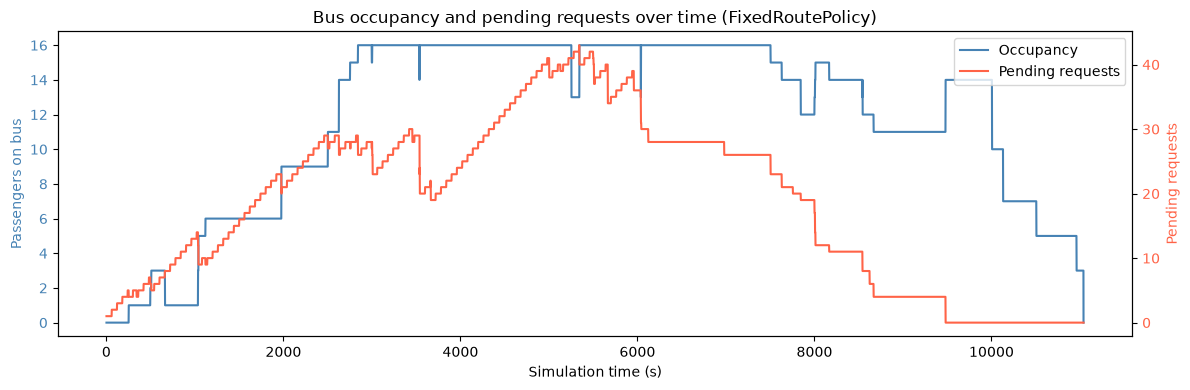

In [9]:
fig, ax1 = plt.subplots(figsize=(12, 4))

ax1.plot(df["sim_time"], df["occupancy"], color="steelblue", label="Occupancy")
ax1.set_xlabel("Simulation time (s)")
ax1.set_ylabel("Passengers on bus", color="steelblue")
ax1.tick_params(axis="y", labelcolor="steelblue")

ax2 = ax1.twinx()
ax2.plot(df["sim_time"], df["pending_count"], color="tomato", label="Pending requests")
ax2.set_ylabel("Pending requests", color="tomato")
ax2.tick_params(axis="y", labelcolor="tomato")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

plt.title("Bus occupancy and pending requests over time (FixedRoutePolicy)")
plt.tight_layout()
plt.show()

## Time distributions

The KPI summary only shows means, which can be skewed by a handful of outliers.
The histograms below show the full distribution for each phase of the passenger
journey. The dashed line marks the mean.

- **Wait time** — time from request creation to boarding; reveals how consistently
  the bus visits each stop.
- **Ride time** — time from boarding to alighting; reflects route efficiency for
  each origin–destination pair.
- **Journey time** — end-to-end: wait + ride combined.

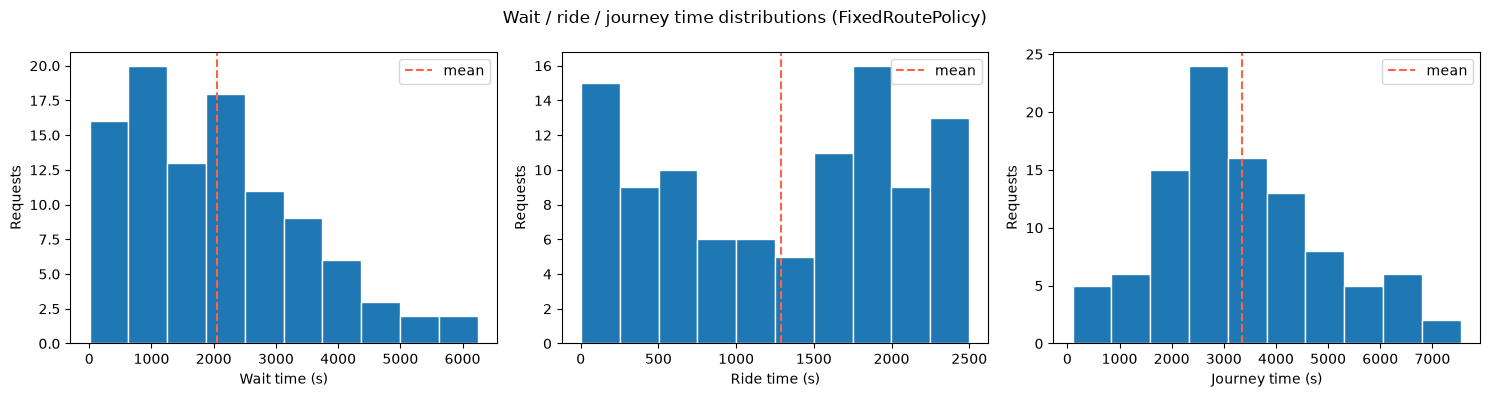

In [10]:
fulfilled_reqs = pool.get_fulfilled()
wait_s    = [r.boarded_at - r.created_at   for r in fulfilled_reqs]
ride_s    = [r.fulfilled_at - r.boarded_at  for r in fulfilled_reqs]
journey_s = [r.fulfilled_at - r.created_at  for r in fulfilled_reqs]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, data, label in zip(
    axes,
    [wait_s, ride_s, journey_s],
    ["Wait time (s)", "Ride time (s)", "Journey time (s)"],
):
    ax.hist(data, bins=min(len(data), 10), edgecolor="white")
    ax.axvline(sum(data) / len(data), color="tomato",
               linestyle="--", label="mean")
    ax.set_xlabel(label)
    ax.set_ylabel("Requests")
    ax.legend()

plt.suptitle("Wait / ride / journey time distributions (FixedRoutePolicy)")
plt.tight_layout()
plt.show()

## Per-request timeline

Each bar represents one passenger, split into two segments:
- **Blue** — wait phase (request created → boarded)
- **Red** — ride phase (boarded → dropped off)

Requests are ordered by creation time. The chart makes it easy to spot which
passengers waited longest, and whether the ride or wait phase dominates total
journey time.

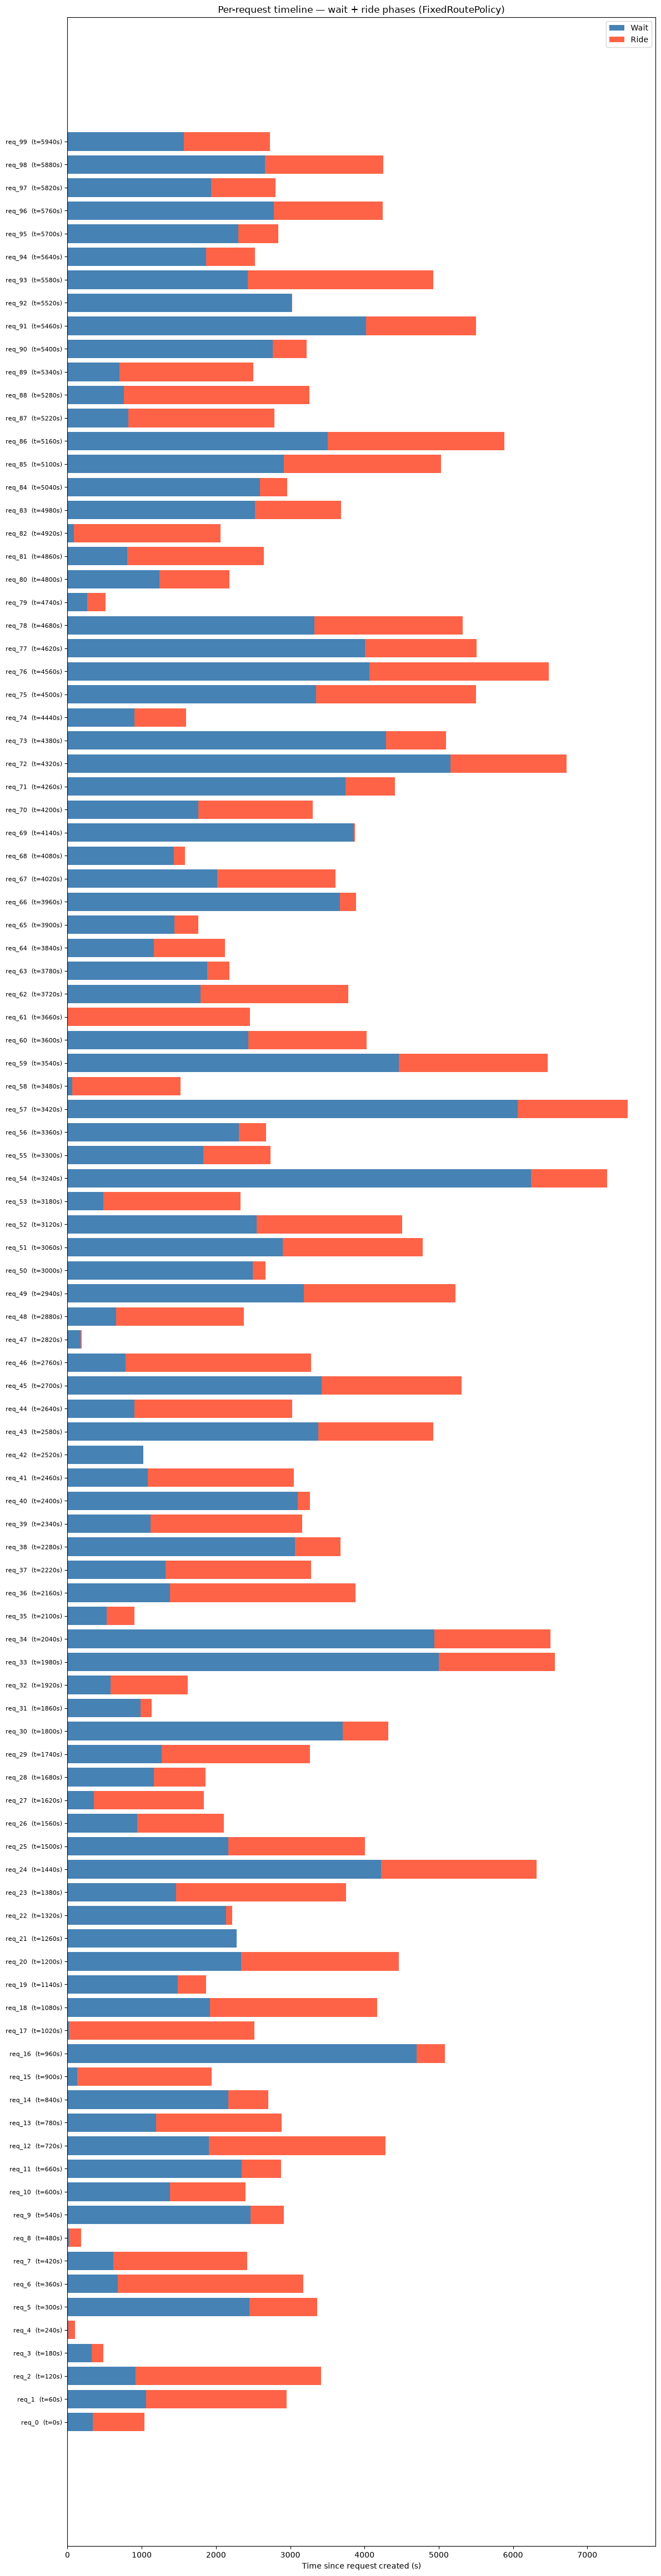

In [11]:
reqs = sorted(pool.get_fulfilled(), key=lambda r: r.created_at)

fig, ax = plt.subplots(figsize=(12, max(4, 0.45 * len(reqs) + 1.5)))
for i, r in enumerate(reqs):
    wait_dur = r.boarded_at - r.created_at
    ride_dur = r.fulfilled_at - r.boarded_at
    ax.barh(i, wait_dur, left=0,
            color="steelblue", label="Wait" if i == 0 else "")
    ax.barh(i, ride_dur, left=wait_dur,
            color="tomato", label="Ride" if i == 0 else "")

ax.set_yticks(range(len(reqs)))
ax.set_yticklabels(
    [f"{r.id}  (t={r.created_at:.0f}s)" for r in reqs], fontsize=8
)
ax.set_xlabel("Time since request created (s)")
ax.set_title("Per-request timeline — wait + ride phases (FixedRoutePolicy)")
ax.legend()
plt.tight_layout()
plt.show()